# 09 Plot AMOC changes

In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from cdrmip_extremes import utils, stats
from cdrmip_extremes.load_processed import load_amoc, load_processed, load_scalar_outputs
from cdrmip_extremes.configs import colour_dict, CDR_MODELS as models, FIG_DIR, PROC_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
amoc_data = load_amoc('CDRMIP')
expt = '1pctCO2-cdr'

In [4]:
gsat = load_processed(PROC_DIR, 'CDRMIP', 'gsat', model_order=models)
gsat_rolling = load_processed(PROC_DIR, 'CDRMIP', 'gsat_rolling', model_order=models)
crossing_years = load_processed(PROC_DIR, 'CDRMIP', 'crossing_year', model_order=models)
gwl_matching_years = load_processed(PROC_DIR, 'CDRMIP', 'gwl_matching_years', model_order=models)

Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/ACCESS-ESM1-5/ACCESS-ESM1-5_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/CESM2/CESM2_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/CNRM-ESM2-1/CNRM-ESM2-1_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/CanESM5/CanESM5_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/GFDL-ESM4/GFDL-ESM4_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/MIROC-ES2L/MIROC-ES2L_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/NorESM2-LM/NorESM2-LM_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gsat/UKESM1-0-LL/UKESM1-0-LL_1pctCO2-cdr_gsat.nc
Loading: /home/563/sc1326/repos/cdrmip_extremes/data/processed/CDRMIP/gs

In [5]:
peak_gsat = utils.flatten_single(
    load_scalar_outputs(PROC_DIR,'CDRMIP','peak_warming')
)

### Identify Changes at 1.5ºC Warming ###

In [6]:
AMOC_changes = {}
for model in models:
    print(model)
    amoc_series = stats._rolling_mean(amoc_data[model]['anom'],21,time_dim='year')
    std_dev = amoc_data[model]['std_dev'].values
    up15_year = int(crossing_years[model][expt].crossing_year.sel(branch='ramp_up',gwl=1.5).values)
    down15_year = int(crossing_years[model][expt].crossing_year.sel(branch='ramp_down',gwl=1.5).values)
    print(up15_year)
    print(down15_year)
    amoc_15_up = amoc_series.sel(year=up15_year).values
    amoc_15_down = amoc_series.sel(year=down15_year).values
    print(model)
    print(f"change in AMOC strength: {amoc_15_down-amoc_15_up} Sv")
    print(f"piControl std_dev: {std_dev}")
    AMOC_changes[model] = np.round(amoc_15_down - amoc_15_up, 2)
    
AMOC_changes = dict(sorted(AMOC_changes.items(), key=lambda item: item[1]))

ACCESS-ESM1-5
59
262
ACCESS-ESM1-5
change in AMOC strength: 3.4788080851236978 Sv
piControl std_dev: 0.9480735063552856
CanESM5
45
290
CanESM5
change in AMOC strength: 3.525626636686779 Sv
piControl std_dev: 0.8339863419532776
CESM2
51
266
CESM2
change in AMOC strength: -4.459324745904832 Sv
piControl std_dev: 0.8172551989555359
CNRM-ESM2-1
59
271
CNRM-ESM2-1
change in AMOC strength: -3.35326219740368 Sv
piControl std_dev: 2.007047653198242
GFDL-ESM4
68
243
GFDL-ESM4
change in AMOC strength: 1.8795337677001953 Sv
piControl std_dev: 1.1683980226516724
MIROC-ES2L
67
236
MIROC-ES2L
change in AMOC strength: -2.3111871537708097 Sv
piControl std_dev: 1.0721344947814941
NorESM2-LM
71
214
NorESM2-LM
change in AMOC strength: -1.0199670791625977 Sv
piControl std_dev: 0.7849041819572449
UKESM1-0-LL
38
332
UKESM1-0-LL
change in AMOC strength: 1.247779164995466 Sv
piControl std_dev: 0.9478689432144165


In [7]:
AMOC_changes

{'CESM2': -4.46,
 'CNRM-ESM2-1': -3.35,
 'MIROC-ES2L': -2.31,
 'NorESM2-LM': -1.02,
 'UKESM1-0-LL': 1.25,
 'GFDL-ESM4': 1.88,
 'ACCESS-ESM1-5': 3.48,
 'CanESM5': 3.53}

In [8]:
models_amoc_ordered = list(AMOC_changes.keys())
models_amoc_ordered

['CESM2',
 'CNRM-ESM2-1',
 'MIROC-ES2L',
 'NorESM2-LM',
 'UKESM1-0-LL',
 'GFDL-ESM4',
 'ACCESS-ESM1-5',
 'CanESM5']

## Plot AMOC timeseries ##

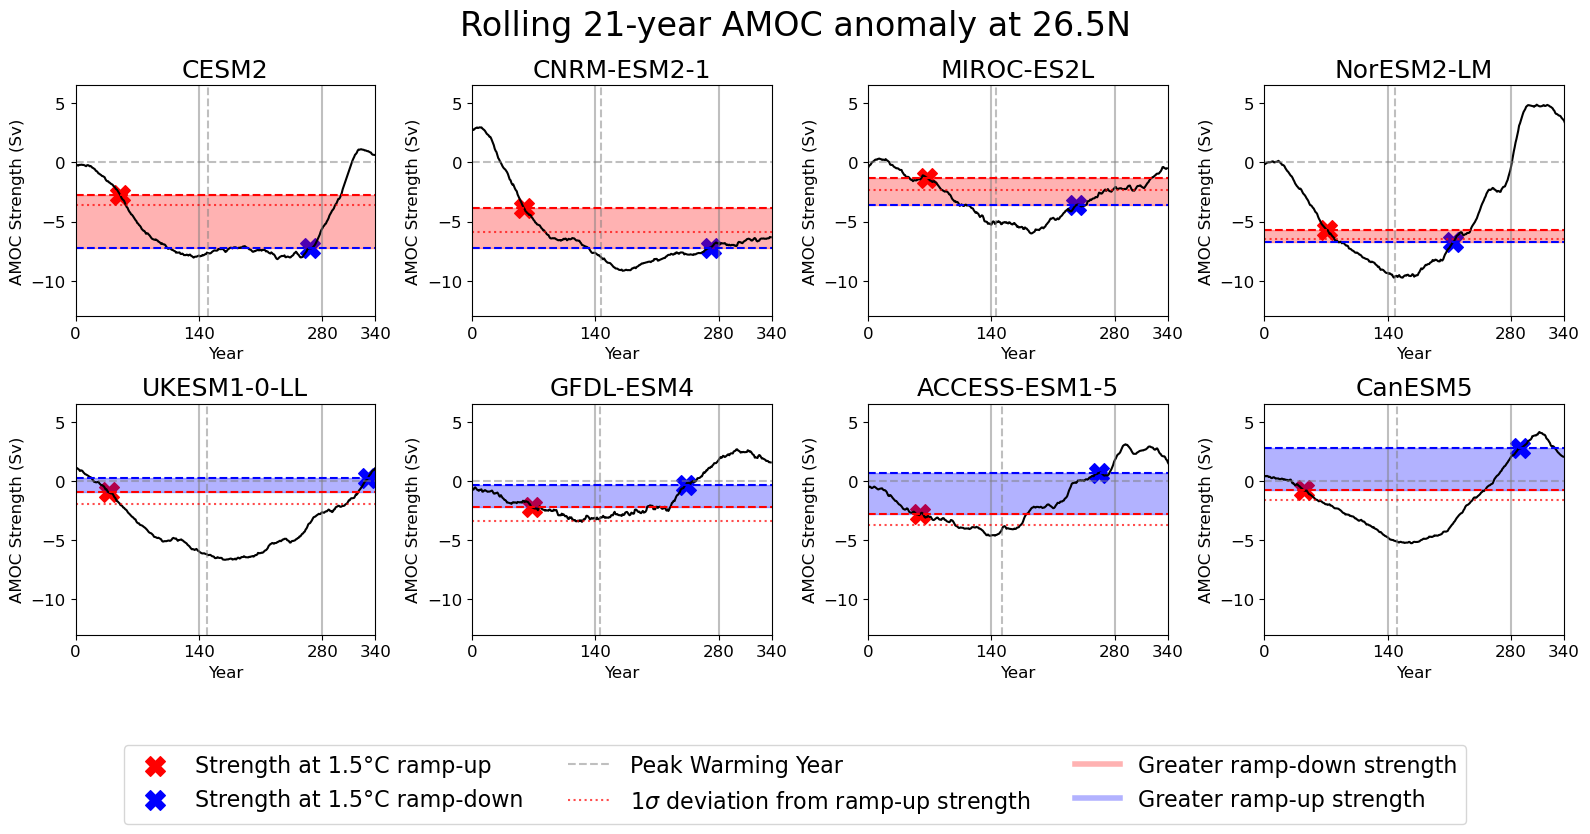

In [9]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(2,4,figsize=(16,7))

for model, ax in zip(models_amoc_ordered,axes.flat):
    
    amoc = utils.rolling(amoc_data[model]['anom'],21,time_dim='year')
    amoc.plot(ax=ax,color='black')

    # plot values at 1.5 degrees
    up15_year = crossing_years[model][expt].crossing_year.sel(branch='ramp_up',gwl=1.5)
    up15_value = amoc.sel(year=up15_year).values
    down15_year = crossing_years[model][expt].crossing_year.sel(branch='ramp_down',gwl=1.5)
    down15_value = amoc.sel(year=down15_year).values

    ax.scatter(up15_year,up15_value,
               marker="X",s=200,
               color='red',
              label='Strength at 1.5°C ramp-up')
    ax.scatter(down15_year,down15_value,
               marker="X",s=200,
               color='blue',
              label='Strength at 1.5°C ramp-down')
    
    # plot peak warming
    ax.axvline(x=peak_gsat[model]['peak_year'],linestyle='--',
               label='Peak Warming Year',
               color='grey',alpha=0.5)

    # other important lines
    ax.axvline(x=140,linestyle='-',
               # label='Peak CO$_2$',
               color='grey',alpha=0.5)
    ax.axvline(x=280,linestyle='-',
               # label='Return to PI CO$_2$',
               color='grey',alpha=0.5)
    ax.axhline(y=0,linestyle='--',color='grey',alpha=0.5)

    # plot shading
    std_dev = amoc_data[model]['std_dev']
    ax.axhline(y=up15_value,
               linestyle='--',color='red')
    ax.axhline(y=down15_value,
               linestyle='--',color='blue',)
    ax.axhline(y=up15_value - std_dev,
               linestyle=':',color='red',alpha=0.7,label='1$\sigma$ deviation from ramp-up strength')

    # Fill between the horizontal lines
    lower_y = min(up15_value, down15_value)
    upper_y = max(up15_value, down15_value)
    color = 'blue' if down15_value > up15_value else 'red'
    ax.fill_betweenx([lower_y, upper_y], ax.get_xlim()[0], ax.get_xlim()[1], color=color, alpha=0.3)
    
    ax.set_title(model,fontsize=18)
    ax.set_ylabel('AMOC Strength (Sv)',fontsize=12)
    ax.set_xlabel('Year',fontsize=12)
    ax.set_ylim([-13,6.5])
    ax.set_xlim([0,340])
    ax.set_xticks([0,140,280,340])
    ax.set_xticklabels(['0','140','280','340'],fontsize=12)
    ax.tick_params(axis='y',labelsize=12)

# legend

handles, labels = axes[0][0].get_legend_handles_labels()

# Create custom legend entries for the shaded areas
custom_lines = [
    Line2D([0], [0], color='red', lw=4, alpha=0.3, label='Down > Up'),
    Line2D([0], [0], color='blue', lw=4, alpha=0.3, label='Up > Down')
]
# Combine them
handles.extend(custom_lines)
labels.extend(['Greater ramp-down strength', 'Greater ramp-up strength'])

fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=16)
# axes[0,3].legend(loc='lower center',bbox_to_anchor=(0.5,-0.1))
fig.suptitle('Rolling 21-year AMOC anomaly at 26.5N',fontsize=24)
fig.tight_layout()

In [10]:
fig.savefig(
    FIG_DIR / "main" / "figure7.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

## Identify changes between end of simulation & equivalent GWL period pre-peak warming

In [11]:
AMOC_changes_final = {}
for model in models:
    print(model)
    amoc_series = stats._rolling_mean(amoc_data[model]['anom'],21,time_dim='year')
    std_dev = amoc_data[model]['std_dev'].values
    up_year = int(gwl_matching_years[model][expt].gwl_matching_years.sel(branch='ramp_up').values)
    down_year = int(gwl_matching_years[model][expt].gwl_matching_years.sel(branch='ramp_down').values)
    print(up_year)
    print(down_year)
    amoc_up = amoc_series.sel(year=up_year).values
    amoc_down = amoc_series.sel(year=down_year).values
    print(model)
    print(f"change in AMOC strength: {amoc_down-amoc_up} Sv")
    print(f"piControl std_dev: {std_dev}")
    AMOC_changes_final[model] = np.round(amoc_down - amoc_up, 2)
    
AMOC_changes_final = dict(sorted(AMOC_changes_final.items(), key=lambda item: item[1]))

ACCESS-ESM1-5
30
330
ACCESS-ESM1-5
change in AMOC strength: 4.041458311535063 Sv
piControl std_dev: 0.9480735063552856
CanESM5
34
330
CanESM5
change in AMOC strength: 3.011467615763346 Sv
piControl std_dev: 0.8339863419532776
CESM2
45
330
CESM2
change in AMOC strength: 3.1287276722136 Sv
piControl std_dev: 0.8172551989555359
CNRM-ESM2-1
31
330
CNRM-ESM2-1
change in AMOC strength: -6.693266102245876 Sv
piControl std_dev: 2.007047653198242
GFDL-ESM4
34
330
GFDL-ESM4
change in AMOC strength: 3.230584671383812 Sv
piControl std_dev: 1.1683980226516724
MIROC-ES2L
17
330
MIROC-ES2L
change in AMOC strength: -1.172822822843279 Sv
piControl std_dev: 1.0721344947814941
NorESM2-LM
30
330
NorESM2-LM
change in AMOC strength: 5.298668815976097 Sv
piControl std_dev: 0.7849041819572449
UKESM1-0-LL
39
330
UKESM1-0-LL
change in AMOC strength: 1.1028925577799478 Sv
piControl std_dev: 0.9478689432144165


In [12]:
AMOC_changes_final

{'CNRM-ESM2-1': -6.69,
 'MIROC-ES2L': -1.17,
 'UKESM1-0-LL': 1.1,
 'CanESM5': 3.01,
 'CESM2': 3.13,
 'GFDL-ESM4': 3.23,
 'ACCESS-ESM1-5': 4.04,
 'NorESM2-LM': 5.3}